<a href="https://colab.research.google.com/github/NICKSTER0506/IoT-Intrusion-Detection-Deployment-Gap/blob/main/DL_IID_with_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=55ccbcda7904b43cb72b320382963a7762387788937509c20fe72bebaf6bd630
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
import psutil
import time
import random
import math
import lime
import lime.lime_tabular

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import requests
from pathlib import Path

url = "https://raw.githubusercontent.com/ndducnha/mahalanobis_dataset/main/7_features/datatest_final_maha_450_test_1.csv"

output = Path(
    "/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/datatest_7_features_1.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

response = requests.get(url, stream=True)
response.raise_for_status()

with open(output, "wb") as f:
    for chunk in response.iter_content(1024 * 1024):
        if chunk:
            f.write(chunk)

print("Downloaded:", output)
print("Size:", round(output.stat().st_size / (1024**2), 2), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Downloaded: /content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/datatest_7_features_1.csv
Size: 5.76 MB


In [3]:
import pandas as pd

path = "/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/datatest_7_features_1.csv"

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nStatistics:")
display(df.describe().T)

Shape: (44999, 7)

First 5 rows:


,2318.4402090840676,0.9095661384526199,-4.139311139656056,18.89359354792485,5.472066192108001,0.3299564440962265,3.611043842811059
0,2369.017404,-1.754597,1.313440,3.161897,-34.433554,1.110685,-18.044512
1,2453.383691,1.088862,-1.227993,-9.131891,-11.780860,-0.086343,-9.914807
2,2433.591570,-5.839638,3.705717,1.830827,5.159389,0.467818,-20.351105
3,2459.126812,2.903708,1.819649,7.543625,27.984036,0.279439,12.624162
4,2389.078792,1.728807,6.556076,6.190018,-34.167965,-0.798856,-7.729004



Data types:
2318.4402090840676    float64
0.9095661384526199    float64
-4.139311139656056    float64
18.89359354792485     float64
5.472066192108001     float64
0.3299564440962265    float64
3.611043842811059     float64
dtype: object

Statistics:


,count,mean,std,min,25%,50%,75%,max
2318.4402090840676,44999.0,2400.084634,48.239944,2199.611246,2367.560809,2400.045211,2432.608640,2596.367862
0.9095661384526199,44999.0,0.008632,3.019591,-13.191679,-2.025444,-0.003796,2.035190,12.358836
-4.139311139656056,44999.0,0.008600,3.004335,-12.668148,-2.024688,0.017977,2.033905,13.023745
18.89359354792485,44999.0,-0.043499,10.031000,-54.216931,-6.799410,-0.069868,6.672912,38.731440
5.472066192108001,44999.0,-0.260803,40.034246,-155.600356,-27.102140,0.081334,26.507046,168.057708
0.3299564440962265,44999.0,0.002206,0.997296,-4.103489,-0.675812,-0.003181,0.672637,4.535973
3.611043842811059,44999.0,0.050417,9.982634,-42.007679,-6.679235,0.011707,6.794519,39.439889


In [4]:
import pandas as pd

path = "/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/datatest_7_features_1.csv"

df = pd.read_csv(path, header=None)

print("Shape:", df.shape)
print("\nUnique values per feature:")
print(df.nunique())

print("\nFirst 10 rows:")
display(df.head(10))

print("\nMissing values:")
print(df.isnull().sum())

Shape: (45000, 7)

Unique values per feature:
0    45000
1    45000
2    45000
3    45000
4    45000
5    45000
6    45000
dtype: int64

First 10 rows:


,0,1,2,3,4,5,6
0,2318.440209,0.909566,-4.139311,18.893594,5.472066,0.329956,3.611044
1,2369.017404,-1.754597,1.313440,3.161897,-34.433554,1.110685,-18.044512
2,2453.383691,1.088862,-1.227993,-9.131891,-11.780860,-0.086343,-9.914807
3,2433.591570,-5.839638,3.705717,1.830827,5.159389,0.467818,-20.351105
4,2459.126812,2.903708,1.819649,7.543625,27.984036,0.279439,12.624162
5,2389.078792,1.728807,6.556076,6.190018,-34.167965,-0.798856,-7.729004
6,2294.342332,1.908894,2.809841,1.714814,32.268396,0.430291,-3.103008
7,2383.765388,2.220037,-0.728659,-6.116192,103.466262,-0.420813,9.403391
8,2463.748331,3.651032,1.545102,-17.675081,76.099924,-0.956088,-1.561354
9,2445.655435,0.409588,-0.976350,2.909231,-37.529545,-0.676690,-0.031919



Missing values:
0    0
1    0
2    0
3    0
4    0
5    0
6    0
dtype: int64


In [6]:
# dataset = pd.read_csv('/content/drive/MyDrive/research_paper/dataset/datatest_7_features_1.csv')
import pandas as pd

dataset_path = "/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/datatest_7_features_1.csv"

dataset = pd.read_csv(dataset_path)

print(dataset.shape)
# display(dataset.head())

(44999, 7)


In [7]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
2318.4402090840676,44999.0,2400.084634,48.239944,2199.611246,2367.560809,2400.045211,2432.608640,2596.367862
0.9095661384526199,44999.0,0.008632,3.019591,-13.191679,-2.025444,-0.003796,2.035190,12.358836
-4.139311139656056,44999.0,0.008600,3.004335,-12.668148,-2.024688,0.017977,2.033905,13.023745
18.89359354792485,44999.0,-0.043499,10.031000,-54.216931,-6.799410,-0.069868,6.672912,38.731440
5.472066192108001,44999.0,-0.260803,40.034246,-155.600356,-27.102140,0.081334,26.507046,168.057708
0.3299564440962265,44999.0,0.002206,0.997296,-4.103489,-0.675812,-0.003181,0.672637,4.535973
3.611043842811059,44999.0,0.050417,9.982634,-42.007679,-6.679235,0.011707,6.794519,39.439889


In [8]:
dataset.head()

,2318.4402090840676,0.9095661384526199,-4.139311139656056,18.89359354792485,5.472066192108001,0.3299564440962265,3.611043842811059
0,2369.017404,-1.754597,1.313440,3.161897,-34.433554,1.110685,-18.044512
1,2453.383691,1.088862,-1.227993,-9.131891,-11.780860,-0.086343,-9.914807
2,2433.591570,-5.839638,3.705717,1.830827,5.159389,0.467818,-20.351105
3,2459.126812,2.903708,1.819649,7.543625,27.984036,0.279439,12.624162
4,2389.078792,1.728807,6.556076,6.190018,-34.167965,-0.798856,-7.729004


In [9]:
dataset.shape

(44999, 7)

In [10]:
dataset.isnull().sum()

,0
2318.4402090840676,0
0.9095661384526199,0
-4.139311139656056,0
18.89359354792485,0
5.472066192108001,0
0.3299564440962265,0
3.611043842811059,0


In [11]:
from sklearn.cluster import KMeans

n_clusters = 2

kmeans = KMeans(n_clusters=n_clusters, random_state=42)
df_clusters = kmeans.fit_predict(dataset)

dataset['cluster'] = df_clusters

print(dataset['cluster'].value_counts())

cluster
0    22593
1    22406
Name: count, dtype: int64


In [13]:
dataset.to_csv(
    '/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/clustered_dataset.csv',
    index=False
)

In [15]:
dataset = pd.read_csv('/content/drive/MyDrive/IoT-IDS-Shared/RF-Fingerprinting/clustered_dataset.csv')

In [16]:
dataset

,2318.4402090840676,0.9095661384526199,-4.139311139656056,18.89359354792485,5.472066192108001,0.3299564440962265,3.611043842811059,cluster
0,2369.017404,-1.754597,1.313440,3.161897,-34.433554,1.110685,-18.044512,0
1,2453.383691,1.088862,-1.227993,-9.131891,-11.780860,-0.086343,-9.914807,1
2,2433.591570,-5.839638,3.705717,1.830827,5.159389,0.467818,-20.351105,1
3,2459.126812,2.903708,1.819649,7.543625,27.984036,0.279439,12.624162,1
4,2389.078792,1.728807,6.556076,6.190018,-34.167965,-0.798856,-7.729004,0
...,...,...,...,...,...,...,...,...
44994,2450.296862,-0.649041,1.243733,26.162420,76.204476,2.071091,25.522839,1
44995,2398.655102,-2.493205,-2.233277,-1.816925,6.189116,0.039580,-8.127218,0
44996,2484.381901,1.244478,-0.711912,13.597908,17.765552,0.775678,-8.039027,1
44997,2423.099763,-4.303185,3.233872,-5.600552,-7.484681,1.682838,8.371839,1


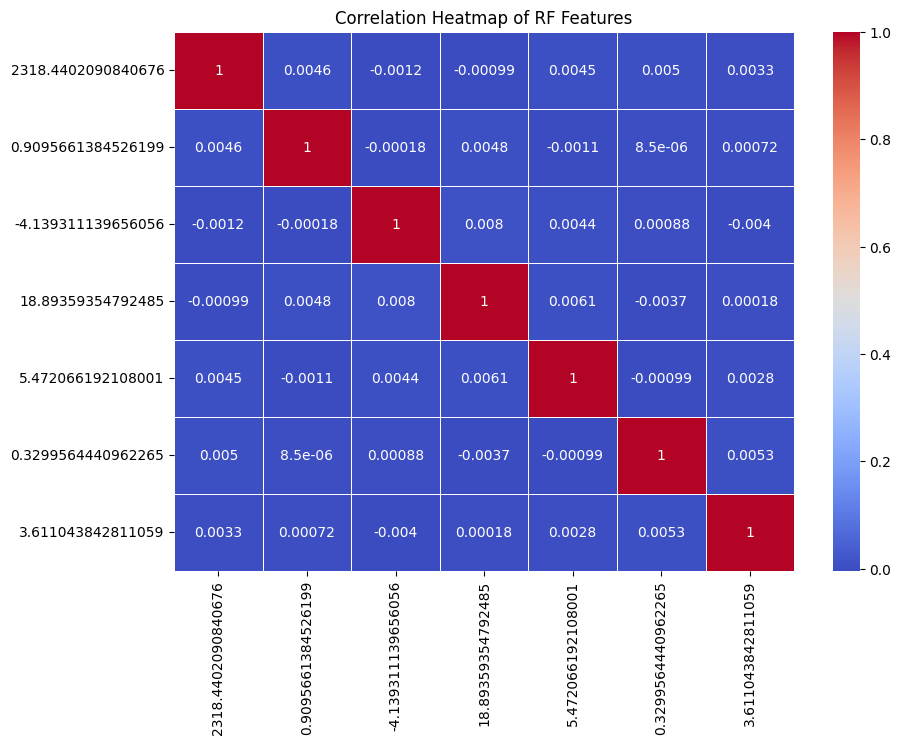

In [22]:
import seaborn as sns

correlation_matrix = dataset.drop(['cluster'], axis=1).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)

plt.title("Correlation Heatmap of RF Features", size=12)

plt.show()

In [23]:
X = dataset.drop(['cluster'], axis=1)
y = dataset['cluster']

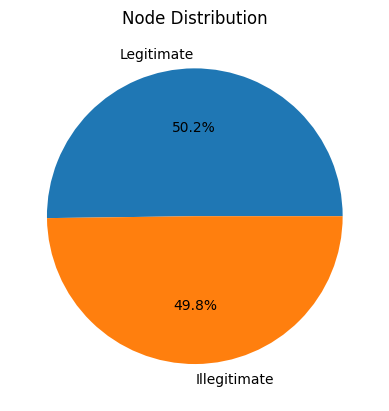

In [24]:
graph_labels = 'Legitimate', 'Illegitimate'
graph_y = y.value_counts()
fig, ax = plt.subplots()
ax.pie(graph_y, labels=graph_labels, autopct='%1.1f%%')
plt.title('Node Distribution')
plt.show()

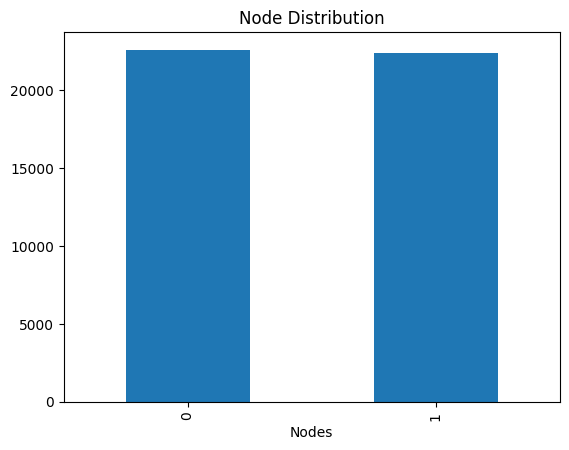

In [25]:
graph_y.plot(kind='bar', xlabel='Nodes')
plt.title('Node Distribution')
plt.show()

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [27]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [28]:
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
        assert len(self.X) == len(self.y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        y = self.y.iloc[idx]
        return x, y

In [29]:
train_dataset = MyDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = MyDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
val_dataset = MyDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [30]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### DNN-BiLSTM

In [31]:
class DNNBiLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, lstm_layers, output_size):
        super(DNNBiLSTM, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        self.lstm = nn.LSTM(input_size=64, hidden_size=hidden_size,
                            num_layers=lstm_layers, batch_first=True,
                            bidirectional=True)

        self.fc3 = nn.Linear(hidden_size * 2, output_size)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = x.float()
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = x.unsqueeze(1)
        lstm_out, _ = self.lstm(x)
        lstm_out = lstm_out[:, -1, :]

        x = self.fc3(lstm_out)
        return self.softmax(x)

    def predict_proba(self, x):
      with torch.no_grad():
          x = torch.tensor(x, dtype=torch.float32)
          output = self.forward(x)
          probabilities = F.softmax(output, dim=1).numpy()
          return probabilities

In [32]:
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs=50):
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(num_epochs):
        model.train()
        total_train_loss, correct_train, total_samples = 0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_train += (predicted == labels).sum().item()
            total_samples += labels.size(0)

        train_loss = total_train_loss / len(train_loader)
        train_accuracy = (correct_train / total_samples) * 100

        # Validation Phase
        model.eval()
        total_val_loss, correct_val, total_val_samples = 0, 0, 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                total_val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                correct_val += (predicted == labels).sum().item()
                total_val_samples += labels.size(0)

        val_loss = total_val_loss / len(val_loader)
        val_accuracy = (correct_val / total_val_samples) * 100

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Train Acc: {train_accuracy:.2f}% | Val Acc: {val_accuracy:.2f}%")

    return train_losses, val_losses, train_accuracies, val_accuracies

In [33]:
def plot_performance(train_losses, val_losses, train_acc, val_acc):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss Plot
    axes[0].plot(train_losses, label="Train Loss", color='blue')
    axes[0].plot(val_losses, label="Validation Loss", color='red')
    axes[0].set_title("Loss Curve")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # Accuracy Plot
    axes[1].plot(train_acc, label="Train Accuracy", color='blue')
    axes[1].plot(val_acc, label="Validation Accuracy", color='red')
    axes[1].set_title("Accuracy Curve")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    plt.show()

In [34]:
input_size = X_train.shape[1]
hidden_size = 64
lstm_layers = 1
output_size = 2
batch_size = 128
num_epochs = 20
learning_rate = 0.0001

In [35]:
model = DNNBiLSTM(input_size, hidden_size, lstm_layers, output_size).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [36]:
train_losses, val_losses, train_acc, val_acc = train(model, train_loader, val_loader, criterion, optimizer, num_epochs)

Epoch 1/20 | Train Loss: 0.4921 | Val Loss: 0.3508 | Train Acc: 89.14% | Val Acc: 98.26%
Epoch 2/20 | Train Loss: 0.3387 | Val Loss: 0.3315 | Train Acc: 98.67% | Val Acc: 99.04%
Epoch 3/20 | Train Loss: 0.3294 | Val Loss: 0.3280 | Train Acc: 98.95% | Val Acc: 98.96%
Epoch 4/20 | Train Loss: 0.3262 | Val Loss: 0.3249 | Train Acc: 99.07% | Val Acc: 99.12%
Epoch 5/20 | Train Loss: 0.3241 | Val Loss: 0.3228 | Train Acc: 99.16% | Val Acc: 99.38%
Epoch 6/20 | Train Loss: 0.3227 | Val Loss: 0.3217 | Train Acc: 99.23% | Val Acc: 99.39%
Epoch 7/20 | Train Loss: 0.3217 | Val Loss: 0.3212 | Train Acc: 99.30% | Val Acc: 99.29%
Epoch 8/20 | Train Loss: 0.3209 | Val Loss: 0.3208 | Train Acc: 99.35% | Val Acc: 99.32%
Epoch 9/20 | Train Loss: 0.3204 | Val Loss: 0.3196 | Train Acc: 99.39% | Val Acc: 99.49%
Epoch 10/20 | Train Loss: 0.3198 | Val Loss: 0.3194 | Train Acc: 99.43% | Val Acc: 99.43%
Epoch 11/20 | Train Loss: 0.3194 | Val Loss: 0.3187 | Train Acc: 99.44% | Val Acc: 99.53%
Epoch 12/20 | Train

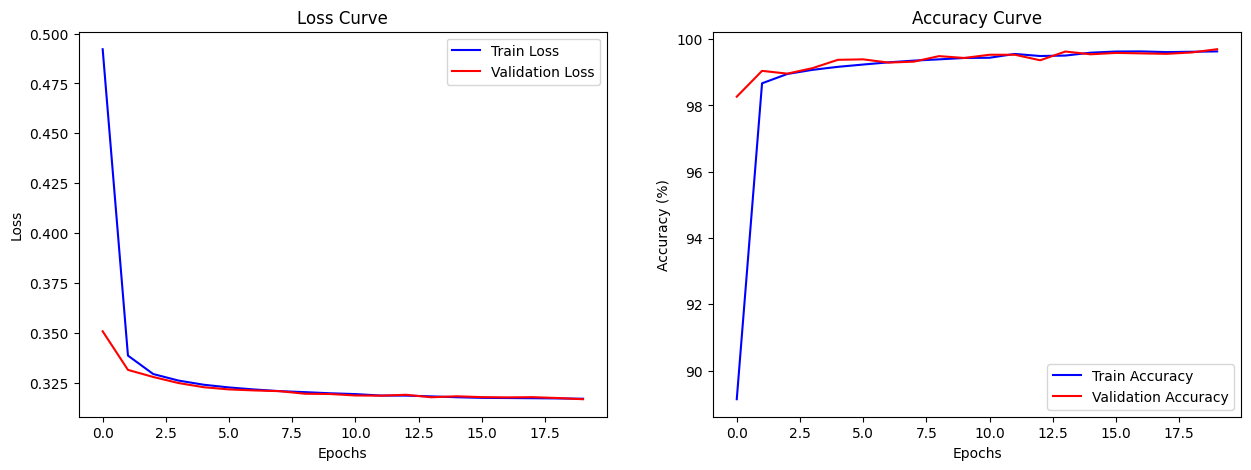

In [37]:
plot_performance(train_losses, val_losses, train_acc, val_acc)

In [38]:
def evaluate_model(model, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    predictions = []
    labels = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device, dtype=torch.float32), y.to(device, dtype=torch.long)
            outputs = model(x)
            loss = criterion(outputs, y)
            test_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y).sum().item()

            predictions.extend(predicted.cpu().numpy())
            labels.extend(y.cpu().numpy())

    # Convert to numpy arrays
    labels_array = np.array(labels)
    predictions_array = np.array(predictions)

    # Compute evaluation metrics
    accuracy = correct / len(test_loader.dataset)
    precision = precision_score(labels, predictions, zero_division=False)
    recall = recall_score(labels, predictions, zero_division=False)
    f1 = f1_score(labels, predictions, zero_division=False)

    # Compute error metrics
    MSE = mean_squared_error(labels_array, predictions_array)
    RMSE = np.sqrt(MSE)
    MAE = mean_absolute_error(labels_array, predictions_array)

    safe_labels = np.where(labels_array == 0, np.nan, labels_array)
    MAPE = np.nanmean(np.abs((labels_array - predictions_array) / safe_labels)) * 100

    # System Resource Utilization
    process = psutil.Process()
    cpu_utilization = psutil.cpu_percent(interval=1)
    memory_usage = process.memory_info().rss / 1024  # Convert to KB

    # Print Results
    print("\n--- Evaluation Metrics ---")
    print(f"Test Loss: {test_loss / len(test_loader):.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

    print("\n--- Error Metrics ---")
    print(f"Mean Absolute Error (MAE): {MAE:.4f}")
    print(f"Mean Squared Error (MSE): {MSE:.4f}")
    print(f"Root Mean Squared Error (RMSE): {RMSE:.4f}")
    print(f"Mean Absolute Percentage Error (MAPE): {MAPE:.2f}%")

    print("\n--- System Resource Utilization ---")
    print(f"CPU Utilization: {cpu_utilization}%")
    print(f"Memory Usage: {memory_usage:.2f} KB")

    # Print Classification Report
    print("\n--- Classification Report ---")
    print(classification_report(labels, predictions, target_names=['Legitimate (0)', 'Malicious (1)']))

    # Plot Confusion Matrix
    conf_matrix = confusion_matrix(labels, predictions)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=['Legitimate (0)', 'Malicious (1)'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.show()


--- Evaluation Metrics ---
Test Loss: 0.3185
Test Accuracy: 0.9941
Precision: 0.9920
Recall: 0.9962
F1 Score: 0.9941

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0059
Mean Squared Error (MSE): 0.0059
Root Mean Squared Error (RMSE): 0.0767
Mean Absolute Percentage Error (MAPE): 0.38%

--- System Resource Utilization ---
CPU Utilization: 53.8%
Memory Usage: 625108.00 KB

--- Classification Report ---
                precision    recall  f1-score   support

Legitimate (0)       1.00      0.99      0.99      4526
 Malicious (1)       0.99      1.00      0.99      4474

      accuracy                           0.99      9000
     macro avg       0.99      0.99      0.99      9000
  weighted avg       0.99      0.99      0.99      9000



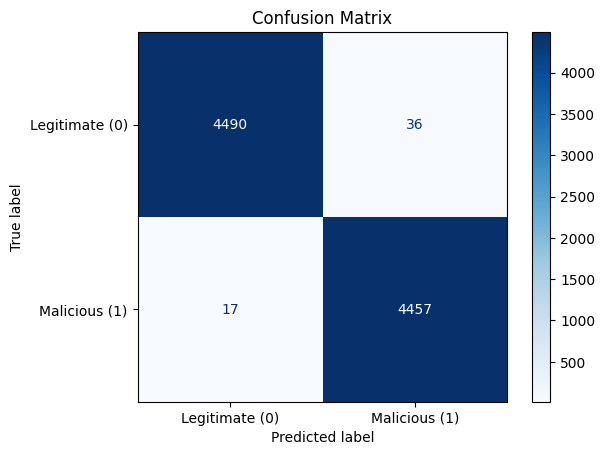

In [39]:
evaluate_model(model, test_loader)

###Fitness (Objective) Function

In [40]:
def train_on_selected_features(selected_features, X, y, epochs=50, batch_size=128):
    selected_features_indices = np.where(selected_features)[0]
    X_selected = X.iloc[:, selected_features_indices]

    scaler = StandardScaler()
    X_selected = scaler.fit_transform(X_selected)

    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

    train_dataset1 = MyDataset(X_train, y_train)
    train_loader1 = DataLoader(train_dataset1, batch_size=64, shuffle=True)
    val_dataset1 = MyDataset(X_val, y_val)
    val_loader1 = DataLoader(val_dataset1, batch_size=64, shuffle=False)

    input_size = X_train.shape[1]
    hidden_size = 64
    lstm_layers = 1
    output_size = 2
    model = DNNBiLSTM(input_size, hidden_size, lstm_layers, output_size).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for batch in train_loader1:
            x, y = batch
            y = y.long()
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0

        with torch.no_grad():
            for batch in val_loader1:
                x, y = batch
                y = y.long()
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == y).sum().item()

        accuracy = correct / len(val_dataset1)

        return 1 - accuracy

In [41]:
class solution:
    def __init__(self):
        self.best = 0
        self.bestIndividual = []
        self.convergence = []
        self.optimizer = ""
        self.objfname = ""
        self.startTime = 0
        self.endTime = 0
        self.executionTime = 0
        self.lb = 0
        self.ub = 0
        self.dim = 0
        self.popnum = 0
        self.maxiers = 0

### GA

In [42]:
def crossover(individualLength, parent1, parent2):
    crossover_point = random.randint(1, individualLength - 1)
    offspring1 = np.concatenate([parent1[:crossover_point], parent2[crossover_point:]])
    offspring2 = np.concatenate([parent2[:crossover_point], parent1[crossover_point:]])
    return offspring1, offspring2

In [43]:
def mutation(individual, individualLength, lb, ub):
    mutationIndex = random.randint(0, individualLength - 1)
    individual[mutationIndex] = 1 - individual[mutationIndex]

In [44]:
def pairSelection(population, scores, popSize):
    def rouletteWheelSelectionId(scores, popSize):
        total_fitness = sum(scores)
        normalized_scores = [score / total_fitness for score in scores]
        cumulative_probs = np.cumsum(normalized_scores)
        random_num = random.random()
        for i, cumulative_prob in enumerate(cumulative_probs):
            if random_num <= cumulative_prob:
                return i

    parent1Id = rouletteWheelSelectionId(scores, popSize)
    parent1 = population[parent1Id].copy()

    parent2Id = parent1Id
    while parent2Id == parent1Id:
        parent2Id = rouletteWheelSelectionId(scores, popSize)

    parent2 = population[parent2Id].copy()

    return parent1, parent2

In [45]:
def mutatePopulaton(population, popSize, mutationProbability, keep, lb, ub):
    for i in range(keep, popSize):
        if random.random() < mutationProbability:
            mutation(population[i], len(population[i]), lb, ub)

In [46]:
def sortPopulation(population, scores):
    sorted_indices = scores.argsort()
    population = population[sorted_indices]
    scores = scores[sorted_indices]
    return population, scores

In [47]:
def crossoverPopulaton(population, scores, popSize, crossoverProbability, keep):
    newPopulation = np.zeros_like(population)
    newPopulation[:keep] = population[:keep]

    for i in range(keep, popSize, 2):
        parent1, parent2 = pairSelection(population, scores, popSize)
        individualLength = len(parent1)

        if random.random() < crossoverProbability:
            offspring1, offspring2 = crossover(individualLength, parent1, parent2)
        else:
            offspring1, offspring2 = parent1.copy(), parent2.copy()

        newPopulation[i] = offspring1
        if i + 1 < popSize:
            newPopulation[i + 1] = offspring2

    return newPopulation

In [48]:
def clearDups(population, lb, ub):
    unique_population = np.unique(population, axis=0)
    num_duplicates = len(population) - len(unique_population)

    if num_duplicates > 0:
        random_individuals = np.random.randint(2, size=(num_duplicates, population.shape[1]))
        unique_population = np.vstack((unique_population, random_individuals))

    return unique_population

In [49]:
def GA(objf, lb, ub, dim, popSize, iters):
    cp = 0.8
    mp = 0.05
    keep = 2
    s = solution()

    bestScore = float("inf")
    bestIndividual = None

    ga = np.random.randint(2, size=(popSize, dim))
    convergence_curve = np.zeros(iters)

    print('GA is optimizing "' + objf.__name__ + '" for feature selection')

    timerStart = time.time()
    s.startTime = time.strftime("%Y-%m-%d-%H-%M-%S")

    for l in range(iters):
        scores = np.array([objf(ind) for ind in ga])

        ga, scores = sortPopulation(ga, scores)

        if scores[0] < bestScore:
            bestScore = scores[0]
            bestIndividual = ga[0]

        convergence_curve[l] = bestScore

        if l % 1 == 0:
            print(f"Iteration {l + 1}, best fitness (error): {bestScore:.4f}")

        ga = crossoverPopulaton(ga, scores, popSize, cp, keep)
        mutatePopulaton(ga, popSize, mp, keep, lb, ub)
        ga = clearDups(ga, lb, ub)

    timerEnd = time.time()
    s.bestIndividual = bestIndividual
    s.bestScore = bestScore
    s.executionTime = timerEnd - timerStart
    s.convergence = convergence_curve
    s.optimizer = "GA"
    s.objfname = objf.__name__

    return s

In [50]:
dim = X.shape[1]
lb = [0] * dim
ub = [1] * dim
popSize = 20
iters = 5

In [51]:
def objective(selected_features):
  return train_on_selected_features(selected_features, X, y)

In [52]:
best_solution = GA(objective, lb, ub, dim, popSize, iters)

print(f"Best feature set: {best_solution.bestIndividual}")
print(f"Best accuracy (1 - best error): {1 - best_solution.bestScore}")

GA is optimizing "objective" for feature selection
Iteration 1, best fitness (error): 0.0088
Iteration 2, best fitness (error): 0.0088
Iteration 3, best fitness (error): 0.0076
Iteration 4, best fitness (error): 0.0069
Iteration 5, best fitness (error): 0.0069
Best feature set: [1 0 1 0 1 0 0]
Best accuracy (1 - best error): 0.9930555555555556


In [53]:
selected_features_ga = best_solution.bestIndividual

In [54]:
selected_features_ga

array([1, 0, 1, 0, 1, 0, 0])

In [55]:
selected_features_ga_original = [X.columns[i] for i, x in enumerate(selected_features_ga) if x == 1]
print(selected_features_ga_original)
print(len(selected_features_ga_original))

['2318.4402090840676', '-4.139311139656056', '5.472066192108001']
3


In [56]:
weights_ga = [1 if x in selected_features_ga_original else 0 for x in X.columns]
print(weights_ga)

[1, 0, 1, 0, 1, 0, 0]


### GA Features

In [57]:
ga_features_indices = [X.columns.get_loc(col) for col in selected_features_ga_original]

In [58]:
X_selected_ga = X.iloc[:, ga_features_indices]

In [59]:
X_train_selected_ga, X_test_selected_ga, y_train_selected_ga, y_test_selected_ga = train_test_split(X_selected_ga, y, test_size=0.3, random_state=42)
X_train_selected_ga, X_val_selected_ga, y_train_selected_ga, y_val_selected_ga = train_test_split(X_train_selected_ga, y_train_selected_ga, test_size=0.2, random_state=42)

In [60]:
X_train_selected_ga = scaler.fit_transform(X_train_selected_ga)
X_test_selected_ga = scaler.transform(X_test_selected_ga)
X_val_selected_ga = scaler.transform(X_val_selected_ga)

In [61]:
train_dataset_selected_ga = MyDataset(X_train_selected_ga, y_train_selected_ga)
train_loader_selected_ga = DataLoader(train_dataset_selected_ga, batch_size=64, shuffle=True)
test_dataset_selected_ga = MyDataset(X_test_selected_ga, y_test_selected_ga)
test_loader_selected_ga = DataLoader(test_dataset_selected_ga, batch_size=64, shuffle=False)
val_dataset_selected_ga = MyDataset(X_val_selected_ga, y_val_selected_ga)
val_loader_selected_ga = DataLoader(val_dataset_selected_ga, batch_size=64, shuffle=False)

In [62]:
model_selected_ga = DNNBiLSTM(input_size=X_train_selected_ga.shape[1], hidden_size=64, lstm_layers=1, output_size=2)
criterion = nn.CrossEntropyLoss()
optimizer_selected_ga = optim.Adam(model_selected_ga.parameters(), lr=0.0001)

In [63]:
train_losses_selected_ga, val_losses_selected_ga, train_acc_selected_ga, val_acc_selected_ga = train(model_selected_ga, train_loader_selected_ga, val_loader_selected_ga, criterion, optimizer_selected_ga)

Epoch 1/50 | Train Loss: 0.4934 | Val Loss: 0.3532 | Train Acc: 94.69% | Val Acc: 98.81%
Epoch 2/50 | Train Loss: 0.3371 | Val Loss: 0.3309 | Train Acc: 99.29% | Val Acc: 99.48%
Epoch 3/50 | Train Loss: 0.3271 | Val Loss: 0.3267 | Train Acc: 99.46% | Val Acc: 99.25%
Epoch 4/50 | Train Loss: 0.3238 | Val Loss: 0.3234 | Train Acc: 99.49% | Val Acc: 99.46%
Epoch 5/50 | Train Loss: 0.3218 | Val Loss: 0.3216 | Train Acc: 99.61% | Val Acc: 99.60%
Epoch 6/50 | Train Loss: 0.3205 | Val Loss: 0.3224 | Train Acc: 99.61% | Val Acc: 99.13%
Epoch 7/50 | Train Loss: 0.3195 | Val Loss: 0.3195 | Train Acc: 99.64% | Val Acc: 99.70%
Epoch 8/50 | Train Loss: 0.3188 | Val Loss: 0.3186 | Train Acc: 99.70% | Val Acc: 99.75%
Epoch 9/50 | Train Loss: 0.3182 | Val Loss: 0.3182 | Train Acc: 99.74% | Val Acc: 99.75%
Epoch 10/50 | Train Loss: 0.3176 | Val Loss: 0.3182 | Train Acc: 99.77% | Val Acc: 99.63%
Epoch 11/50 | Train Loss: 0.3172 | Val Loss: 0.3171 | Train Acc: 99.75% | Val Acc: 99.79%
Epoch 12/50 | Train

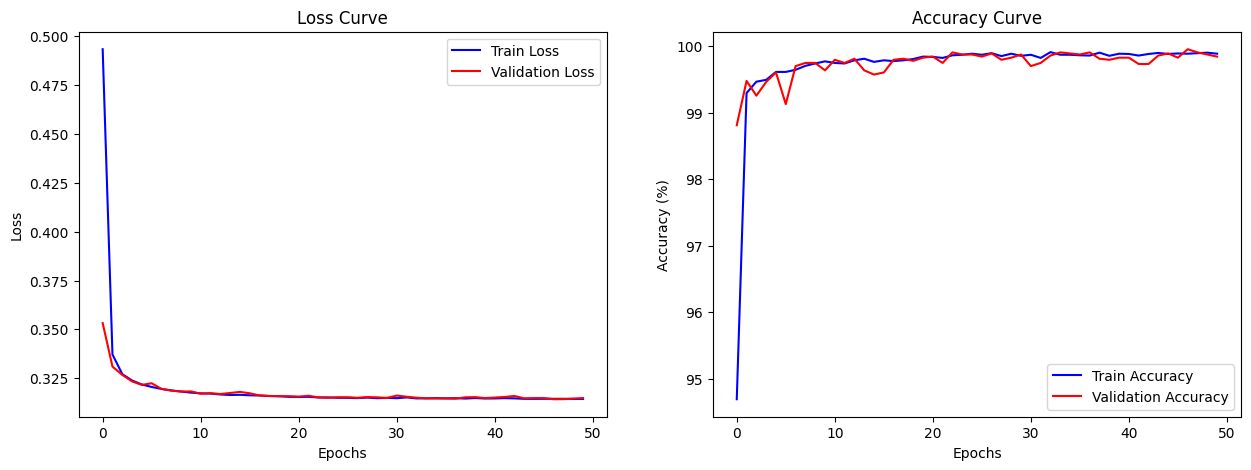

In [64]:
plot_performance(train_losses_selected_ga, val_losses_selected_ga, train_acc_selected_ga, val_acc_selected_ga)


--- Evaluation Metrics ---
Test Loss: 0.3151
Test Accuracy: 0.9982
Precision: 0.9970
Recall: 0.9994
F1 Score: 0.9982

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0018
Mean Squared Error (MSE): 0.0018
Root Mean Squared Error (RMSE): 0.0422
Mean Absolute Percentage Error (MAPE): 0.06%

--- System Resource Utilization ---
CPU Utilization: 1.5%
Memory Usage: 626464.00 KB

--- Classification Report ---
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00      6771
 Malicious (1)       1.00      1.00      1.00      6729

      accuracy                           1.00     13500
     macro avg       1.00      1.00      1.00     13500
  weighted avg       1.00      1.00      1.00     13500



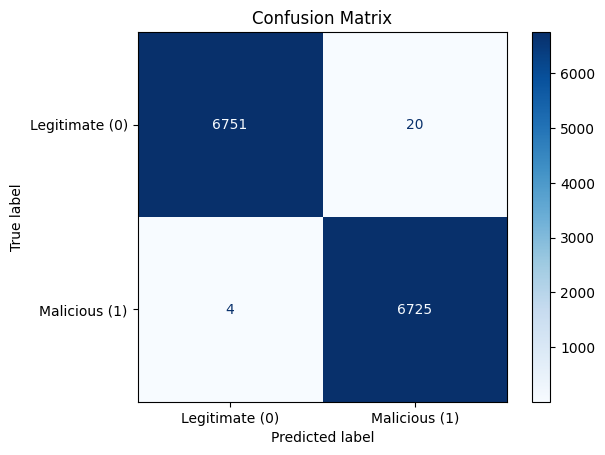

In [65]:
evaluate_model(model_selected_ga, test_loader_selected_ga)

### LIME for DNN-BiLSTM with All Features

In [66]:
explainer1 = lime.lime_tabular.LimeTabularExplainer(X_train,
                                                   feature_names=X.columns.tolist(),
                                                   mode='classification',
                                                   discretize_continuous=True)

In [67]:
i = 10
exp1 = explainer1.explain_instance(
    data_row=X_test[i],
    predict_fn=model.predict_proba,
    num_features=X_train.shape[1]
)

In [68]:
y_test_selected_ga.iloc[i]

np.int64(0)

In [69]:
exp1.show_in_notebook(show_table=True, show_predicted_value=True)

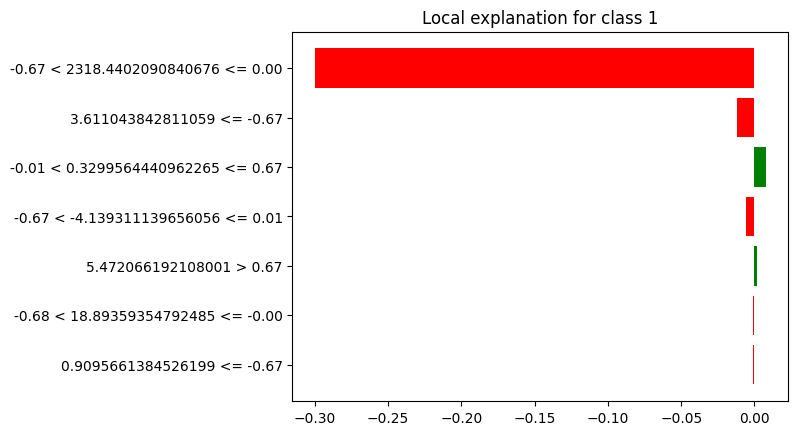

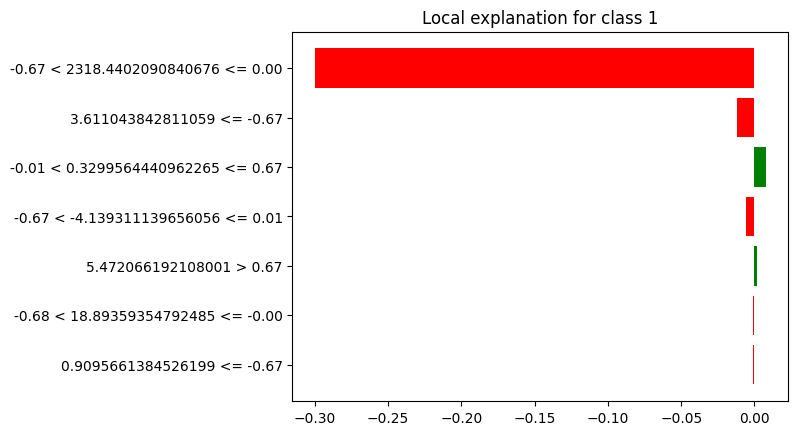

In [70]:
exp1.as_pyplot_figure()

In [71]:
exp1.save_to_file('/content/drive/MyDrive/research_paper/lime_explanation.html')

In [72]:
feature_contributions1 = exp1.as_map()[1]
print("Feature Contributions (index-based):", feature_contributions1)

Feature Contributions (index-based): [(np.int64(0), np.float64(-0.2999838384140218)), (np.int64(6), np.float64(-0.012090948330018537)), (np.int64(5), np.float64(0.007765608917197044)), (np.int64(2), np.float64(-0.005768061086489296)), (np.int64(4), np.float64(0.0018166838451199809)), (np.int64(3), np.float64(-0.0010399081302735333)), (np.int64(1), np.float64(-0.0007334811074979842))]


### LIME for DNN-BiLSTM with GA Features

In [73]:
explainer2 = lime.lime_tabular.LimeTabularExplainer(X_train_selected_ga,
                                                   feature_names=X_selected_ga,
                                                   mode='classification',
                                                   discretize_continuous=True)

In [74]:
j=10
exp2 = explainer2.explain_instance(
    data_row=X_test_selected_ga[j],
    predict_fn=model_selected_ga.predict_proba,
    num_features=X_train_selected_ga.shape[1]
)

In [75]:
exp2.show_in_notebook(show_table=True, show_predicted_value=True)

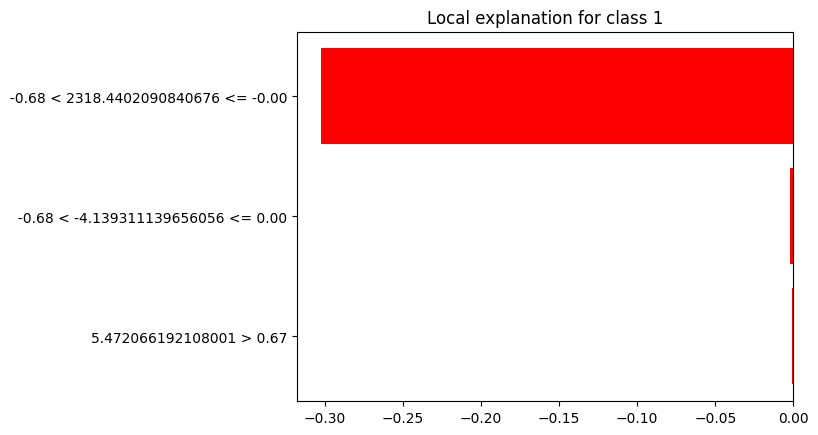

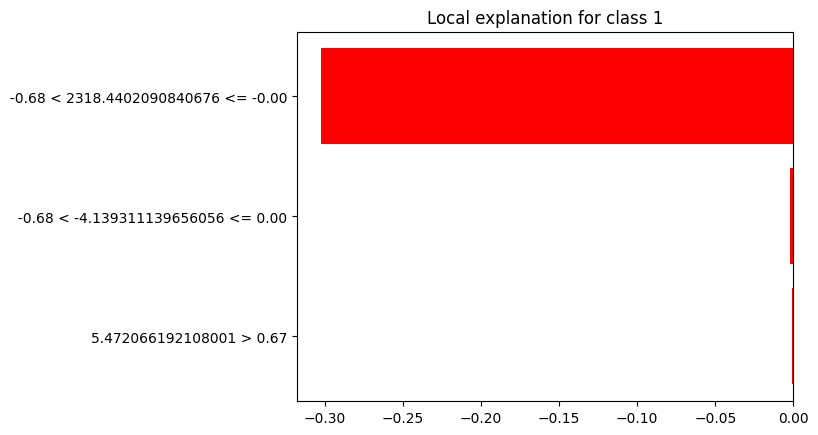

In [76]:
exp2.as_pyplot_figure()

In [77]:
exp2.save_to_file('/content/drive/MyDrive/research_paper/lime_explanation_ga.html')

In [78]:
feature_contributions2 = exp2.as_map()[1]
print("Feature Contributions (index-based):", feature_contributions2)

Feature Contributions (index-based): [(np.int64(0), np.float64(-0.3027236842189009)), (np.int64(1), np.float64(-0.0017664524907402416)), (np.int64(2), np.float64(-0.0010238847897138911))]


Model Size

In [79]:
torch.save(model.state_dict(), '/content/drive/MyDrive/research_paper/dnn_bilstm_model.pth')

model_size1 = os.path.getsize('/content/drive/MyDrive/research_paper/dnn_bilstm_model.pth') / 1024
print(f"Model Size: {model_size1:.2f} KB")

Model Size: 302.54 KB


In [80]:
torch.save(model_selected_ga.state_dict(), '/content/drive/MyDrive/research_paper/ga_selected_model.pth')

model_size_ga = os.path.getsize('/content/drive/MyDrive/research_paper/ga_selected_model.pth') / 1024
print(f"Model Size: {model_size_ga:.2f} KB")

Model Size: 300.56 KB


### Dynamic Quantization model

In [81]:
import torch.quantization
quantized_model_ga = torch.quantization.quantize_dynamic(
    model_selected_ga,
    {nn.LSTM},
    dtype=torch.qint8
)

/tmp/ipykernel_10565/723413438.py:2: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model_ga = torch.quantization.quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dty


--- Evaluation Metrics ---
Test Loss: 0.3151
Test Accuracy: 0.9981
Precision: 0.9970
Recall: 0.9993
F1 Score: 0.9981

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0019
Mean Squared Error (MSE): 0.0019
Root Mean Squared Error (RMSE): 0.0430
Mean Absolute Percentage Error (MAPE): 0.07%

--- System Resource Utilization ---
CPU Utilization: 2.0%
Memory Usage: 659676.00 KB

--- Classification Report ---
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00      6771
 Malicious (1)       1.00      1.00      1.00      6729

      accuracy                           1.00     13500
     macro avg       1.00      1.00      1.00     13500
  weighted avg       1.00      1.00      1.00     13500



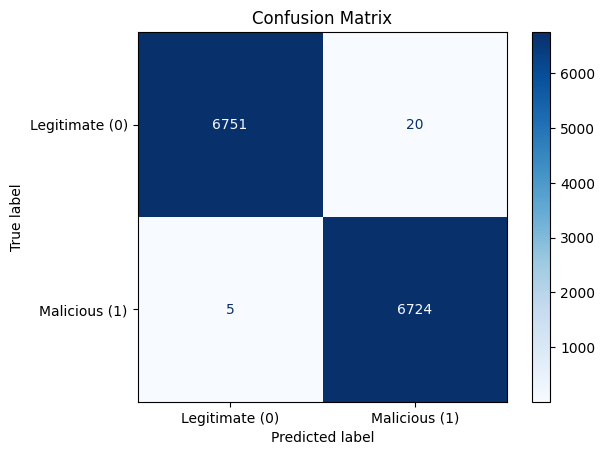

In [82]:
evaluate_model(quantized_model_ga, test_loader_selected_ga)

In [83]:
torch.save(quantized_model_ga.state_dict(), '/content/drive/MyDrive/research_paper/ga_quantised_model.pth')

quantized_ga_size = os.path.getsize('/content/drive/MyDrive/research_paper/ga_quantised_model.pth') / 1024
print(f"Model Size: {quantized_ga_size:.2f} KB")

Model Size: 109.33 KB
